In [1]:
# ---------------------------------------------------------------- parameters
FULL = True         # True: 65 devices, 50 epochs, same protocol as the main results
                     #       (~20 min per variant on 2 cores with PARALLEL = 2; ~40 min for both)
                     # False: short smoke test (20 devices, 20 epochs, ~10 min in total)
RERUN_BASE = False   # FULL mode only: retrain the one-layer ChaRRNet too, instead of loading its saved results
PARALLEL = 4         # training runs launched at once (set to your number of CPU cores)

import json, os, subprocess, sys, time
import numpy as np
import matplotlib.pyplot as plt
import ag, models, sim

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(0)

# Ablation: adding SurReal's layers to ChaRRNet

ChaRRNet builds on **SurReal** (Chakraborty, Xing & Yu, arXiv:1910.11334), but the reproduction uses only SurReal's core: the $\mathbb{R}^+\times U(1)$ manifold, one weighted-Fréchet-mean (wFM) convolution and the distance transform. SurReal's own networks (its Tables I–II) stack **two wFM layers, each followed by a manifold nonlinearity**. This notebook tests whether those additions help multipath robustness.

| variant | equivariant part |
|---|---|
| `base` | wFM (1→8 channels, 4 windows, stride 2) — the main results |
| `deep` | wFM → wFM (8→8, 3 windows, stride 1) |
| `deep_gt` | wFM → **G-transport** → wFM → **G-transport** |

Everything after the equivariant part is identical: the invariant distance layer still outputs 32 maps × 3 time steps × 128 bins, so the real-valued CNN, and therefore almost all of the ~314k parameters, is unchanged. The second wFM layer adds 192 parameters and G-transport another 32.

## 1. Which SurReal nonlinearity can be used here?

SurReal proposes two nonlinearities, both defined in the tangent space $(\ln r, \theta)$:

* **tangent ReLU**: $\ln r \mapsto \max(\ln r, 0)$ and $\theta \mapsto \max(\theta, 0)$;
* **G-transport**: for each channel $c$, act on every value with one learned group element $(e^{a_c}, R(\phi_c))$, i.e. $(\ln r, \theta) \mapsto (\ln r + a_c,\ \theta + \phi_c)$.

In ChaRRNet the channel acts on a frequency bin as a translation by $(\ln|H(f)|, \angle H(f))$, and every layer before the distance transform must commute with that translation. G-transport is itself a translation, so it commutes. Tangent ReLU does not: $\max(x + h, 0) \ne \max(x, 0) + h$, so it would destroy the channel equivariance (SurReal only needs invariance to one global complex scale, where the issue does not arise in the same way). The cell below checks both claims numerically, which is why only G-transport is tested.

In [2]:
pop = sim.DevicePopulation(65, np.random.default_rng(1), pole_sigma=0.1)
X, _ = sim.make_dataset(pop, 1, None, rng)
X = X[:8]
S = models.stft(X)
H = np.fft.fftshift(np.fft.fft(sim.TRAIN_NLOS200.draw(rng), models.NFFT))
x0 = np.concatenate(models.to_manifold(S), 1)
x1 = np.concatenate(models.to_manifold(S * H), 1)            # ideal channel action

for v in ['base', 'deep', 'deep_gt']:
    m = models.ChaRRNet(65, np.random.default_rng(0), variant=v)
    for p in m.params():                                      # random, non-trivial weights
        p.data = rng.standard_normal(p.shape).astype(np.float32)
    z0, z1 = m.invariant(x0).data, m.invariant(x1).data
    print(f'{v:8s} invariant-layer change under the ideal channel: {np.linalg.norm(z1 - z0) / np.linalg.norm(z0):.2e}')

# tangent ReLU applied after the first wFM layer instead of G-transport
m = models.ChaRRNet(65, np.random.default_rng(0), variant='base')
for p in m.params():
    p.data = rng.standard_normal(p.shape).astype(np.float32)
def with_trelu(x):
    lr, th = m.equivariant(x)
    lr, th = lr.relu(), th.relu()                              # tangent ReLU
    return models.invariant_layer(lr, th, m.winv, m.K2, m.S2).data
z0, z1 = with_trelu(x0), with_trelu(x1)
print(f'{"tReLU":8s} invariant-layer change under the ideal channel: {np.linalg.norm(z1 - z0) / np.linalg.norm(z0):.2e}')

base     invariant-layer change under the ideal channel: 4.20e-05
deep     invariant-layer change under the ideal channel: 2.69e-05
deep_gt  invariant-layer change under the ideal channel: 1.08e-05
tReLU    invariant-layer change under the ideal channel: 7.63e-01


## 2. Model sizes and a gradient check

In [3]:
for v in ['base', 'deep', 'deep_gt']:
    m = models.ChaRRNet(65, np.random.default_rng(0), variant=v)
    print(f'{v:8s} {sum(p.data.size for p in m.params()):>9,d} parameters')

# finite-difference check of the new layers (float64, small problem)
Xs, ys = sim.make_dataset(sim.DevicePopulation(5, np.random.default_rng(2), pole_sigma=0.1), 1, None, rng)
m = models.ChaRRNet(5, np.random.default_rng(0), variant='deep_gt')
for p in m.params():
    p.data = p.data.astype(np.float64)
for name in ['gt_a1', 'gt_p1', 'gt_a2', 'gt_p2']:              # move G-transport away from identity
    getattr(m, name).data = 0.3 * rng.standard_normal(getattr(m, name).shape)
x = models.ChaRRNet.prep(Xs).astype(np.float64)
ag.cross_entropy(m(x), ys).backward()
worst = 0.0
for name in ['weq', 'weq2', 'gt_a1', 'gt_p1', 'gt_a2', 'gt_p2', 'winv']:
    P = getattr(m, name); g = P.grad.copy(); P.grad = None
    for _ in range(3):
        i = tuple(rng.integers(0, s) for s in P.shape); e = 1e-6
        P.data[i] += e; lp = ag.cross_entropy(m(x), ys).data
        P.data[i] -= 2 * e; lm = ag.cross_entropy(m(x), ys).data
        P.data[i] += e
        num = (lp - lm) / (2 * e)
        if abs(num) > 1e-8:
            worst = max(worst, abs(num - g[i]) / (abs(num) + abs(g[i])))
print(f'max relative gradient error in the equivariant/invariant layers: {worst:.1e}')

base       314,049 parameters
deep       314,241 parameters
deep_gt    314,273 parameters
max relative gradient error in the equivariant/invariant layers: 6.5e-07


## 3. Training

Same Table I protocol as the main results: train on **pristine** bursts or on the **nLOS-200** channel model, test on pristine bursts and on six unseen channel models. The data seed is fixed, so all variants see identical training and test sets.

* `FULL = True`: 65 devices, 100 bursts/device, 50 epochs. The one-layer `base` results are loaded from `res_charrnet_pristine.json` / `res_charrnet_nlos.json` unless `RERUN_BASE = True`.
* `FULL = False`: 20 devices, 20 epochs, and `base` is retrained at the same settings so the comparison is fair. This only shows that everything runs; the short runs are too small to rank the variants reliably.

Each run is a subprocess (single-threaded BLAS), `PARALLEL` at a time; logs go to `log_abl_*.txt`.

In [4]:
tag = 'full' if FULL else 'short'
args = (['--epochs', '50'] if FULL else
        ['--devices', '20', '--train_per_dev', '100', '--test_per_dev', '10', '--epochs', '20'])
variants = ['deep', 'deep_gt'] + (['base'] if (RERUN_BASE or not FULL) else [])
jobs = [(v, t, f'res_abl_{tag}_{v}_{"p" if t == "Pristine" else "n"}.json')
        for v in variants for t in ['Pristine', 'nLOS 200']]

env = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')
t0 = time.time()
for i in range(0, len(jobs), PARALLEL):
    procs = []
    for v, t, out in jobs[i:i + PARALLEL]:
        cmd = [sys.executable, 'train.py', '--models', 'charrnet', '--variant', v, '--train_sets', t,
               '--out', out] + args
        procs.append(subprocess.Popen(cmd, env=env, stdout=open(f'log_abl_{out[8:-5]}.txt', 'w'),
                                      stderr=subprocess.STDOUT))
    for p in procs:
        p.wait()
    print(f'{min(i + PARALLEL, len(jobs))}/{len(jobs)} runs done after {(time.time() - t0) / 60:.0f} min',
          flush=True)

4/4 runs done after 28 min


## 4. Results

In [5]:
tests = ['Pristine', 'nLOS 10', 'LOS 10', 'nLOS 30', 'LOS 100', 'nLOS 400', 'LOS 400']
res = {}
for v, t, out in jobs:
    r = json.load(open(out))['results'][f'charrnet|{t}']
    res[(v, t)] = r
if FULL and not RERUN_BASE:
    for t, f in [('Pristine', 'res_charrnet_pristine.json'), ('nLOS 200', 'res_charrnet_nlos.json')]:
        res[('base', t)] = json.load(open(f))['results'][f'charrnet|{t}']

order = [v for v in ['base', 'deep', 'deep_gt'] if (v, 'Pristine') in res]
summary = {}
for t in ['Pristine', 'nLOS 200']:
    print(f'\ntrained on {t}')
    print(f"{'test set':10s}" + ''.join(f'{v:>10s}' for v in order))
    for s in tests:
        print(f'{s:10s}' + ''.join(f"{100 * res[(v, t)]['test'][s]:10.1f}" for v in order))
    mp = {v: float(np.mean([100 * res[(v, t)]['test'][s] for s in tests[1:]])) for v in order}
    print(f"{'mean MP':10s}" + ''.join(f'{mp[v]:10.1f}' for v in order))
    print(f"{'val (ID)':10s}" + ''.join(f"{100 * res[(v, t)]['val']:10.1f}" for v in order))
    for v in order:
        summary[f'{v}|{t}'] = dict(params=res[(v, t)]['params'], val=res[(v, t)]['val'],
                                   test=res[(v, t)]['test'], mean_multipath=mp[v] / 100)

json.dump(dict(mode=tag, results=summary), open(f'ablation_results_{tag}.json', 'w'), indent=1)
print(f'\nsaved ablation_results_{tag}.json')


trained on Pristine
test set        base      deep   deep_gt
Pristine        79.1      55.3      64.5
nLOS 10         35.2      35.2      44.8
LOS 10          35.6      35.2      42.5
nLOS 30         35.2      35.1      41.5
LOS 100         36.9      34.1      41.8
nLOS 400        34.3      34.2      42.2
LOS 400         34.7      33.1      41.8
mean MP         35.3      34.5      42.4
val (ID)        77.5      54.9      67.2

trained on nLOS 200
test set        base      deep   deep_gt
Pristine        58.2      36.2      56.9
nLOS 10         68.8      38.5      60.7
LOS 10          65.4      38.3      57.9
nLOS 30         67.4      36.9      58.5
LOS 100         64.9      35.8      54.8
nLOS 400        65.1      37.4      57.5
LOS 400         66.2      37.7      57.3
mean MP         66.3      37.4      57.8
val (ID)        68.2      39.7      57.8

saved ablation_results_full.json


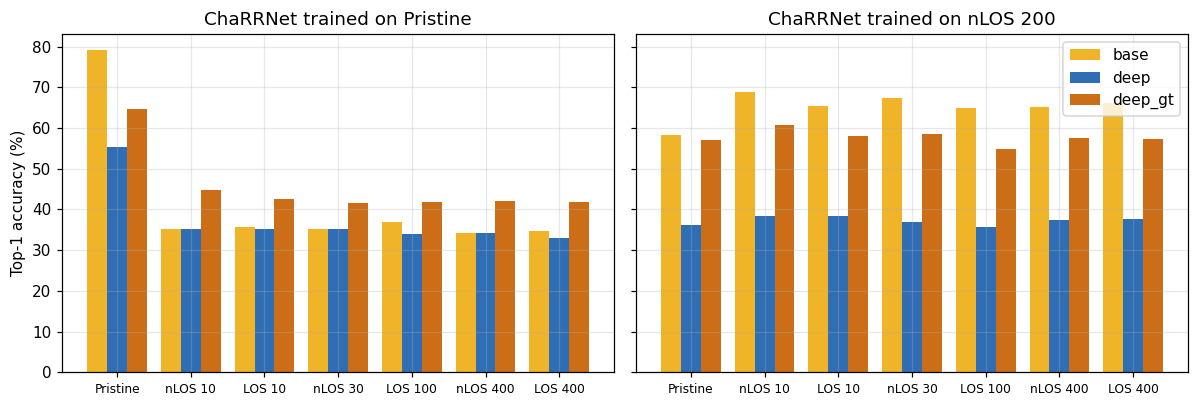

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
cols = {'base': '#f0b429', 'deep': '#2f6db5', 'deep_gt': '#cb6e17'}
x = np.arange(len(tests))
for k, t in enumerate(['Pristine', 'nLOS 200']):
    for j, v in enumerate(order):
        ax[k].bar(x + (j - (len(order) - 1) / 2) * 0.27,
                  [100 * res[(v, t)]['test'][s] for s in tests], 0.27, color=cols[v], label=v)
    ax[k].set_xticks(x, tests, fontsize=8)
    ax[k].set_title(f'ChaRRNet trained on {t}')
ax[0].set_ylabel('Top-1 accuracy (%)'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'ablation_{tag}.png', dpi=130); plt.show()

## 5. What to look for

* **Mean multipath accuracy** (the six unseen channel models) is the quantity ChaRRNet is meant to improve. Compare `deep` with `base` for the effect of depth, and `deep_gt` with `deep` for the effect of G-transport.
* **Pristine-trained columns** test robustness without any channel augmentation. Here the equivariance of the layers is the only thing protecting the model, so architecture changes should show most clearly.
* **`val (ID)`** is in-distribution validation accuracy. If a variant raises it without raising multipath accuracy, it is fitting the training channel rather than becoming more robust.
* Results from one seed vary by a few points; differences smaller than that are not meaningful.

**Files to share:** `ablation_results_full.json` (or `_short`), `ablation_full.png`, and the `log_abl_*.txt` training logs.